In [1]:
from google.colab import drive
from pathlib import Path
from collections import Counter

drive.mount("/content/drive")

# Change this if necessary.
DATASET = Path("/content/drive/MyDrive/Dataset")

if not DATASET.is_dir():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET}\n"
        "Update DATASET to the correct Google Drive folder path."
    )

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

for split in ["train", "test"]:
    image_dir = DATASET / split / "img"
    annotation_dir = DATASET / split / "ann"

    print(f"\n{'=' * 15} {split.upper()} {'=' * 15}")

    for folder in [image_dir, annotation_dir]:
        if not folder.is_dir():
            raise FileNotFoundError(f"Required folder missing: {folder}")

    images = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    )
    annotations = sorted(
        p for p in annotation_dir.rglob("*")
        if p.is_file() and not p.name.startswith(".")
    )

    print("Images:", len(images))
    print("Annotation files:", len(annotations))
    print("Annotation extensions:", dict(Counter(
        p.suffix.lower() or "(no extension)" for p in annotations
    )))

    # Show one example per annotation format.
    for extension in sorted({p.suffix.lower() for p in annotations}):
        sample = next(p for p in annotations if p.suffix.lower() == extension)
        print(f"\nSample annotation: {sample.name}")
        try:
            with sample.open("r", encoding="utf-8") as f:
                print(f.read(3000))
        except UnicodeDecodeError:
            print("Binary annotation file; format needs inspection.")

print("\nDataset configuration files:")
for name in ["data.yaml", "data.yml", "classes.txt", "obj.names"]:
    matches = sorted(DATASET.rglob(name))
    for path in matches[:5]:
        print(f"\n{path.relative_to(DATASET)}")
        print(path.read_text(encoding="utf-8")[:3000])

Mounted at /content/drive

=============== TRAIN ===============
Images: 391
Annotation files: 392
Annotation extensions: {'.json': 392}

Sample annotation: M0101_img000016.jpg.json
{
    "description": "",
    "tags": [
        {
            "id": 20426569,
            "tagId": 31789,
            "name": "sequence",
            "value": "M0101",
            "labelerLogin": "inbox@datasetninja.com",
            "createdAt": "2024-03-05T11:42:04.796Z",
            "updatedAt": "2024-03-05T11:42:04.796Z"
        },
        {
            "id": 20426570,
            "tagId": 31798,
            "name": "daylight",
            "value": null,
            "labelerLogin": "inbox@datasetninja.com",
            "createdAt": "2024-03-05T11:42:04.796Z",
            "updatedAt": "2024-03-05T11:42:04.796Z"
        },
        {
            "id": 20426571,
            "tagId": 31802,
            "name": "medium alt",
            "value": null,
            "labelerLogin": "inbox@datasetninja.com",
     

In [4]:
import json
from pathlib import Path
from collections import Counter, defaultdict

DATASET = Path("/content/drive/MyDrive/Dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

audit = {}
issues = []

for split in ["train", "test"]:
    image_dir = DATASET / split / "img"
    ann_dir = DATASET / split / "ann"

    images = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    annotations = sorted(ann_dir.rglob("*.json"))
    used_annotations = set()
    records = []

    class_boxes = Counter()
    class_images = Counter()
    sequence_images = Counter()
    sequence_classes = defaultdict(Counter)

    for image in images:
        relative = image.relative_to(image_dir)

        # Standard Supervisely naming: image.jpg.json
        annotation = ann_dir / relative.parent / (relative.name + ".json")

        if not annotation.is_file():
            issues.append(f"{split}: missing annotation for {relative}")
            continue

        used_annotations.add(annotation)

        try:
            data = json.loads(annotation.read_text(encoding="utf-8"))
            width = data["size"]["width"]
            height = data["size"]["height"]
            if width <= 0 or height <= 0:
                raise ValueError("Invalid image dimensions")
        except Exception as exc:
            issues.append(f"{split}: cannot read {annotation.name}: {exc}")
            continue

        sequences = [
            str(tag["value"])
            for tag in data.get("tags", [])
            if tag.get("name") == "sequence" and tag.get("value") is not None
        ]

        if len(set(sequences)) != 1:
            issues.append(f"{split}: missing/ambiguous sequence for {relative}")
            continue

        sequence = sequences[0]
        sequence_images[sequence] += 1
        present_classes = set()

        for index, obj in enumerate(data.get("objects", [])):
            try:
                label = obj["classTitle"]
                if obj.get("geometryType") != "rectangle":
                    raise ValueError("Non-rectangle geometry")

                points = obj["points"]["exterior"]
                if len(points) != 2:
                    raise ValueError("Expected two rectangle corners")

                (x1, y1), (x2, y2) = points

                if not (0 <= x1 < x2 <= width and
                        0 <= y1 < y2 <= height):
                    raise ValueError(f"Invalid/out-of-bounds box: {points}")

                class_boxes[label] += 1
                sequence_classes[sequence][label] += 1
                present_classes.add(label)

            except Exception as exc:
                issues.append(
                    f"{split}: {relative}, object {index}: {exc}"
                )

        class_images.update(present_classes)
        records.append({
            "image": str(image),
            "annotation": str(annotation),
            "sequence": sequence,
        })

    orphan_annotations = [
        str(p.relative_to(ann_dir))
        for p in annotations if p not in used_annotations
    ]

    audit[split] = {
        "records": records,
        "sequences": set(sequence_images),
        "class_boxes": class_boxes,
    }

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Successfully read image/annotation pairs:", len(records))
    print("Unmatched annotation files:", orphan_annotations)
    print("Object counts by class:", dict(sorted(class_boxes.items())))
    print("Images containing each class:", dict(sorted(class_images.items())))
    print("Images per sequence:", dict(sorted(sequence_images.items())))
    print("Objects per sequence:")
    for sequence in sorted(sequence_classes):
        print(f"  {sequence}: {dict(sorted(sequence_classes[sequence].items()))}")

overlap = audit["train"]["sequences"] & audit["test"]["sequences"]
print("\nSequences shared between TRAIN and TEST:", sorted(overlap))

print("\nAnnotation issues:", len(issues))
for issue in issues[:30]:
    print(" -", issue)

if len(issues) > 30:
    print(f"... plus {len(issues) - 30} additional issues")

print("\nExisting local YOLO image folders:")
for split in ["train", "val", "test"]:
    folder = Path("/content/uavdt_small/images") / split
    count = sum(
        p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        for p in folder.rglob("*")
    ) if folder.exists() else 0
    print(f"{split}: {count}")


--- TRAIN ---
Images: 391
Successfully read image/annotation pairs: 391
Unmatched annotation files: ['M0201_img000059 (1).jpg.json']
Object counts by class: {'bus': 232, 'car': 6833, 'truck': 370}
Images containing each class: {'bus': 129, 'car': 384, 'truck': 210}
Images per sequence: {'M0101': 6, 'M0201': 15, 'M0202': 7, 'M0204': 4, 'M0206': 7, 'M0207': 12, 'M0210': 10, 'M0301': 5, 'M0401': 7, 'M0402': 5, 'M0501': 4, 'M0603': 59, 'M0604': 30, 'M0605': 7, 'M0702': 13, 'M0703': 14, 'M0704': 15, 'M0901': 20, 'M0902': 5, 'M1002': 15, 'M1003': 14, 'M1005': 7, 'M1006': 14, 'M1008': 3, 'M1102': 11, 'M1201': 22, 'M1202': 14, 'M1304': 14, 'M1305': 5, 'M1306': 27}
Objects per sequence:
  M0101: {'bus': 1, 'car': 69, 'truck': 2}
  M0201: {'bus': 2, 'car': 80, 'truck': 11}
  M0202: {'car': 89}
  M0204: {'car': 34}
  M0206: {'bus': 3, 'car': 64}
  M0207: {'bus': 8, 'car': 7}
  M0210: {'car': 69, 'truck': 28}
  M0301: {'car': 21}
  M0401: {'car': 116, 'truck': 6}
  M0402: {'car': 115}
  M0501: {'

Second cell to run

In [6]:
import json
import shutil
from pathlib import Path
from collections import Counter
import numpy as np
from PIL import Image

SOURCE = Path("/content/drive/MyDrive/Dataset")
OUTPUT = Path("/content/yolo_vehicle_baseline")
SPLIT_FILE = SOURCE / "experiment_splits" / "three_class_v1.json"

CLASSES = ["car", "truck", "bus"]
CLASS_ID = {name: i for i, name in enumerate(CLASSES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
SEED = 42

def read_records(split):
    records = []
    image_root = SOURCE / split / "img"

    for image in sorted(image_root.rglob("*")):
        if not image.is_file() or image.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative = image.relative_to(image_root)
        annotation = (
            SOURCE / split / "ann" / relative.parent / (relative.name + ".json")
        )
        data = json.loads(annotation.read_text())
        width, height = data["size"]["width"], data["size"]["height"]

        # Check actual image dimensions and readability.
        with Image.open(image) as im:
            assert im.size == (width, height), f"Size mismatch: {image}"
            im.verify()

        sequence_values = {
            str(t["value"]) for t in data.get("tags", [])
            if t.get("name") == "sequence" and t.get("value") is not None
        }
        assert len(sequence_values) == 1, f"Invalid sequence: {image}"
        sequence = next(iter(sequence_values))

        counts = Counter()
        labels = []

        for obj in data.get("objects", []):
            name = obj["classTitle"]
            counts[name] += 1

            assert obj["geometryType"] == "rectangle", image
            (x1, y1), (x2, y2) = obj["points"]["exterior"]
            assert 0 <= x1 < x2 <= width, image
            assert 0 <= y1 < y2 <= height, image

            if name in CLASS_ID:
                labels.append(
                    f"{CLASS_ID[name]} "
                    f"{(x1 + x2) / (2 * width):.8f} "
                    f"{(y1 + y2) / (2 * height):.8f} "
                    f"{(x2 - x1) / width:.8f} "
                    f"{(y2 - y1) / height:.8f}"
                )

        records.append({
            "key": relative.as_posix(),
            "image": image,
            "sequence": sequence,
            "counts": counts,
            "labels": labels,
        })

    return records

train_source = read_records("train")
test_source = read_records("test")

assert all(
    set(r["counts"]) <= set(CLASSES) for r in train_source
), "Unexpected training class."

excluded = [r for r in test_source if "vehicle" in r["counts"]]
assert all(
    set(r["counts"]) == {"vehicle"} for r in excluded
), "Mixed generic and specific labels found; stop for review."

test_records = [r for r in test_source if "vehicle" not in r["counts"]]
assert all(
    set(r["counts"]) <= set(CLASSES) for r in test_records
), "Unexpected test class."

assert len(train_source) == 391, "Training dataset changed; review counts."
assert len(test_records) == 243 and len(excluded) == 361, (
    "Test dataset changed; review counts."
)

# Reuse the saved split if this cell is rerun.
if SPLIT_FILE.exists():
    manifest = json.loads(SPLIT_FILE.read_text())
    assert manifest["classes"] == CLASSES
    assert manifest["source_train_images"] == sorted(
        r["key"] for r in train_source
    ), "Training files changed since the split was saved."
    assert manifest["test_images"] == sorted(
        r["key"] for r in test_records
    ), "Test files changed since the split was saved."
    val_sequences = set(manifest["validation_sequences"])
else:
    sequences = sorted({r["sequence"] for r in train_source})
    groups = {
        s: [r for r in train_source if r["sequence"] == s]
        for s in sequences
    }

    # Balance the validation fraction for image counts, class object
    # counts, and images containing each class, subject to sequence separation.
    def features(records):
        return np.array(
            [len(records)]
            + [sum(r["counts"][c] for r in records) for c in CLASSES]
            + [sum(r["counts"][c] > 0 for r in records) for c in CLASSES],
            dtype=float,
        )

    group_features = np.array([features(groups[s]) for s in sequences])
    totals = group_features.sum(axis=0)
    rng = np.random.default_rng(SEED)
    best = None

    # This search uses training labels only; test results play no role.
    for _ in range(20000):
        chosen = rng.random(len(sequences)) < 0.20
        selected = group_features[chosen].sum(axis=0)
        remaining = totals - selected

        if not 0.15 <= selected[0] / totals[0] <= 0.25:
            continue
        if np.any(selected[1:] == 0) or np.any(remaining[1:] == 0):
            continue

        fractions = selected / totals
        score = (
            2 * abs(fractions[0] - 0.20)
            + np.mean(abs(fractions[1:4] - 0.20))
            + np.mean(abs(fractions[4:] - 0.20))
        )
        if best is None or score < best[0]:
            best = (score, chosen.copy())

    assert best is not None, "No suitable grouped split found; stop for review."
    val_sequences = {
        s for s, chosen in zip(sequences, best[1]) if chosen
    }

    manifest = {
        "seed": SEED,
        "classes": CLASSES,
        "validation_sequences": sorted(val_sequences),
        "source_train_images": sorted(r["key"] for r in train_source),
        "test_images": sorted(r["key"] for r in test_records),
        "excluded_generic_test_images": sorted(r["key"] for r in excluded),
    }
    SPLIT_FILE.parent.mkdir(parents=True, exist_ok=True)
    SPLIT_FILE.write_text(json.dumps(manifest, indent=2))

splits = {
    "train": [r for r in train_source if r["sequence"] not in val_sequences],
    "val": [r for r in train_source if r["sequence"] in val_sequences],
    "test": test_records,
}

sequence_sets = {
    name: {r["sequence"] for r in records}
    for name, records in splits.items()
}
assert not sequence_sets["train"] & sequence_sets["val"]
assert not sequence_sets["train"] & sequence_sets["test"]
assert not sequence_sets["val"] & sequence_sets["test"]

# Refuse to mix this output with pre-existing files.
assert not OUTPUT.exists(), (
    f"{OUTPUT} already exists. Stop and share this message before rerunning."
)

for split, records in splits.items():
    image_dir = OUTPUT / "images" / split
    label_dir = OUTPUT / "labels" / split
    image_dir.mkdir(parents=True)
    label_dir.mkdir(parents=True)

    for index, record in enumerate(records):
        # Numbered filenames avoid collisions from nested source folders.
        name = f"{index:05d}_{record['image'].stem}"
        shutil.copy2(
            record["image"],
            image_dir / (name + record["image"].suffix.lower()),
        )
        (label_dir / (name + ".txt")).write_text(
            "\n".join(record["labels"]) + ("\n" if record["labels"] else "")
        )

yaml_path = OUTPUT / "data.yaml"
yaml_path.write_text(
    f"path: {OUTPUT}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "names:\n"
    "  0: car\n"
    "  1: truck\n"
    "  2: bus\n"
)

print("\nPREPARATION SUMMARY")
for split, records in splits.items():
    counts = Counter()
    for record in records:
        counts.update(record["counts"])
    assert all(counts[c] > 0 for c in CLASSES)
    print(
        f"{split}: {len(records)} images | "
        f"{len(sequence_sets[split])} sequences | "
        f"objects: {dict((c, counts[c]) for c in CLASSES)}"
    )

print("\nValidation sequences:", sorted(val_sequences))
print("Excluded generic-vehicle test images:", len(excluded))
print("Sequence overlap: NONE")
print("Fixed split saved to:", SPLIT_FILE)
print("YOLO configuration:", yaml_path)
print("\nPREPARATION PASSED — share this summary before training.")


PREPARATION SUMMARY
train: 312 images | 23 sequences | objects: {'car': 5455, 'truck': 291, 'bus': 188}
val: 79 images | 7 sequences | objects: {'car': 1378, 'truck': 79, 'bus': 44}
test: 243 images | 19 sequences | objects: {'car': 6283, 'truck': 185, 'bus': 164}

Validation sequences: ['M0206', 'M0210', 'M0501', 'M1006', 'M1008', 'M1304', 'M1306']
Excluded generic-vehicle test images: 361
Sequence overlap: NONE
Fixed split saved to: /content/drive/MyDrive/Dataset/experiment_splits/three_class_v1.json
YOLO configuration: /content/yolo_vehicle_baseline/data.yaml

PREPARATION PASSED — share this summary before training.


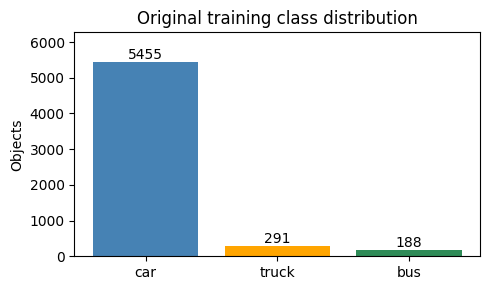

In [7]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

RUNS = Path("/content/drive/MyDrive/YOLO_vehicle_experiments")
FIGURES = RUNS / "final_figures"
FIGURES.mkdir(parents=True, exist_ok=True)

names = ["car", "truck", "bus"]
label_dir = Path("/content/yolo_vehicle_baseline/labels/train")
files = list(label_dir.glob("*.txt"))
assert len(files) == 312, "Restore the original 312-image training set."

counts = Counter()
for file in files:
    for line in file.read_text().splitlines():
        if line.strip():
            counts[int(line.split()[0])] += 1

assert [counts[i] for i in range(3)] == [5455, 291, 188]

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(names, [counts[i] for i in range(3)],
              color=["steelblue", "orange", "seagreen"])
ax.bar_label(bars)
ax.set(title="Original training class distribution", ylabel="Objects")
ax.set_ylim(0, max(counts.values()) * 1.15)
fig.tight_layout()
fig.savefig(FIGURES / "training_class_distribution.png", dpi=200)
plt.show()

In [ ]:
%pip install --upgrade ultralytics "numpy>=2.1,<2.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 117.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 65.3 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


Baseline final model

In [ ]:
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
import sys
import json
import yaml
import torch
import ultralytics
from ultralytics import YOLO

ROOT = Path("/content/yolo_vehicle_baseline")
RUNS = Path("/content/drive/MyDrive/YOLO_vehicle_experiments")
RUN_NAME = "baseline_yolov8s_v3_tuned_v1"
RUN_DIR = RUNS / RUN_NAME
MANIFEST = ROOT / "train_minority_repeat2.txt"

assert torch.cuda.is_available(), "GPU unavailable."
assert ultralytics.__version__ == "8.4.210", "Ultralytics version changed."
assert MANIFEST.is_file(), "Oversampling manifest missing."
assert not RUN_DIR.exists(), "Run already exists; stop before rerunning."

paths = MANIFEST.read_text().splitlines()
assert len(paths) == 530 and len(set(paths)) == 312
assert all(Path(p).is_file() for p in paths), "Training images missing."

config = yaml.safe_load((ROOT / "data.yaml").read_text())
config["train"] = str(MANIFEST)
DATA = ROOT / "data_oversampled.yaml"
DATA.write_text(yaml.safe_dump(config, sort_keys=False))

RUNS.mkdir(parents=True, exist_ok=True)
LOG = RUNS / f"{RUN_NAME}.log"
console = sys.stdout

def epoch_update(trainer):
    metrics = trainer.metrics
    print(
        f"Epoch {trainer.epoch + 1}/{trainer.epochs} | "
        f"mAP50={metrics.get('metrics/mAP50(B)', float('nan')):.3f} | "
        f"mAP50-95={metrics.get('metrics/mAP50-95(B)', float('nan')):.3f}",
        file=console,
        flush=True,
    )

print("Training started.", flush=True)

with LOG.open("w", buffering=1) as log:
    with redirect_stdout(log), redirect_stderr(log):
        # Fresh COCO initialization for comparison with V3.
        model = YOLO("yolov8s.pt")
        model.add_callback("on_fit_epoch_end", epoch_update)

        model.train(
            data=str(DATA),
            project=str(RUNS),
            name=RUN_NAME,

            epochs=150,
            patience=40,
            imgsz=640,
            batch=8,
            device=0,
            workers=2,
            cache=False,

            optimizer="SGD",
            lr0=0.003,           # V3: 0.01
            lrf=0.01,
            momentum=0.937,
            weight_decay=0.001, # V3: 0.0005
            warmup_epochs=5.0,
            cos_lr=True,

            mosaic=1.0,
            close_mosaic=10,
            mixup=0.05,         # V3: 0.0
            fliplr=0.5,
            flipud=0.0,
            degrees=0.0,
            translate=0.1,
            scale=0.5,
            hsv_h=0.015,
            hsv_s=0.7,
            hsv_v=0.4,

            seed=42,
            deterministic=True,
            amp=True,
            single_cls=False,
            save=True,
            plots=True,
            verbose=False,
        )

        RUN_DIR = Path(model.trainer.save_dir)
        BEST = RUN_DIR / "weights/best.pt"
        assert BEST.is_file(), "Best checkpoint missing."

        tuned = YOLO(str(BEST))
        metrics = tuned.val(
            data=str(DATA),
            split="val",
            imgsz=640,
            batch=8,
            device=0,
            workers=2,
            conf=0.001,
            iou=0.7,
            max_det=300,
            augment=False,
            plots=True,
            project=str(RUNS),
            name=f"{RUN_NAME}_validation",
            verbose=False,
        )

summary = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
    "per_class": {},
}

for i, class_id in enumerate(metrics.box.ap_class_index):
    name = tuned.names[int(class_id)]
    summary["per_class"][name] = {
        "AP50": float(metrics.box.ap50[i]),
        "AP50_95": float(metrics.box.ap[i]),
    }

(RUN_DIR / "validation_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("\nTUNED V3 — VALIDATION")
print(f"P={summary['precision']:.3f}  R={summary['recall']:.3f}")
print(
    f"mAP50={summary['mAP50']:.3f}  "
    f"mAP50-95={summary['mAP50_95']:.3f}"
)
for name, values in summary["per_class"].items():
    print(f"{name}: AP50={values['AP50']:.3f}")

print(f"Change vs V3 mAP50: {summary['mAP50'] - 0.494:+.3f}")
print("Weights:", BEST)

Training started.
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_vehicle_baseline/data_oversampled.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolov8s

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


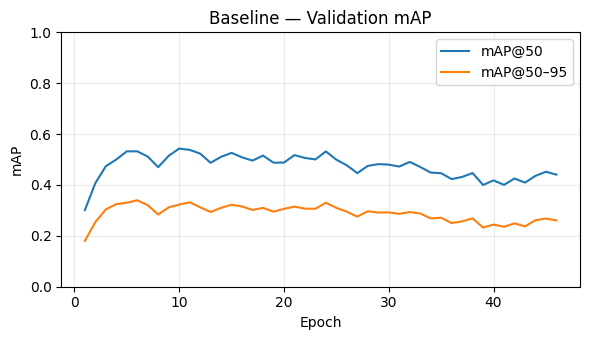

In [11]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

drive.mount("/content/drive")

RUN = Path(
    "/content/drive/MyDrive/YOLO_vehicle_experiments/"
    "baseline_yolov8s_v3_tuned_v1"
)

history = pd.read_csv(RUN / "results.csv")
history.columns = history.columns.str.strip()

fig, ax = plt.subplots(figsize=(6, 3.5))

ax.plot(
    history["epoch"],
    history["metrics/mAP50(B)"],
    label="mAP@50",
)
ax.plot(
    history["epoch"],
    history["metrics/mAP50-95(B)"],
    label="mAP@50–95",
)

ax.set(
    title="Baseline — Validation mAP",
    xlabel="Epoch",
    ylabel="mAP",
    ylim=(0, 1),
)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(RUN / "baseline_validation_map.png", dpi=250)
plt.show()

Save the architecture

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

CODE_DIR = Path("/content/drive/MyDrive/YOLO_vehicle_experiments/model_code")
CODE_DIR.mkdir(parents=True, exist_ok=True)

code = '''
import torch
import torch.nn as nn
from ultralytics.models.yolo.detect import DetectionTrainer


class ECANeckBlock(nn.Module):
    def __init__(self, block, kernel_size=3):
        super().__init__()
        self.block = block
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.channel_conv = nn.Conv1d(
            1, 1, kernel_size,
            padding=kernel_size // 2,
            bias=False,
        )
        # 2 * sigmoid(0) = 1: preserve initial features.
        nn.init.zeros_(self.channel_conv.weight)

    def forward(self, x):
        x = self.block(x)
        descriptor = self.pool(x).squeeze(-1).transpose(1, 2)
        attention = 2.0 * torch.sigmoid(self.channel_conv(descriptor))
        attention = attention.transpose(1, 2).unsqueeze(-1)
        return x * attention


def add_eca(model):
    if any(isinstance(m, ECANeckBlock) for m in model.modules()):
        return model

    head = model.model[-1]
    indices = list(head.f)
    assert len(indices) == 3, "Expected three detection scales."

    parameter = next(model.parameters())

    for index in indices:
        assert index >= 0
        old = model.model[index]
        assert old.__class__.__name__ == "C2f", (
            f"Unexpected neck block at {index}: {type(old).__name__}"
        )

        new = ECANeckBlock(old).to(
            device=parameter.device,
            dtype=parameter.dtype,
        )

        for attribute in ["i", "f"]:
            setattr(new, attribute, getattr(old, attribute))

        new.type = "ECANeckBlock"
        new.np = sum(p.numel() for p in new.parameters())
        new.train(old.training)
        model.model[index] = new

    return model


class ECATrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(
            cfg=cfg, weights=weights, verbose=verbose
        )
        return add_eca(model)
'''

(CODE_DIR / "eca_neck.py").write_text(code)
print("ECA architecture saved.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ECA architecture saved.


In [ ]:
%pip install --no-cache-dir --force-reinstall --no-deps ultralytics==8.4.210

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.1 MB/s  0:00:00
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.4.210
    Uninstalling ultralytics-8.4.210:
      Successfully uninstalled ultralytics-8.4.210


In [ ]:
import importlib.metadata
print("Installed:", importlib.metadata.version("ultralytics"))

Installed: 8.4.210


In [ ]:
import sys
import contextlib
import torch
import ultralytics

sys.path.insert(0, str(CODE_DIR))

from ultralytics import YOLO
from eca_neck import add_eca, ECANeckBlock

assert ultralytics.__version__ == "8.4.210", (
    f"Version changed: {ultralytics.__version__}"
)
assert torch.cuda.is_available(), "Enable GPU."

with open("/content/eca_check.log", "w") as log:
    with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
        wrapper = YOLO("yolov8s.pt")
        net = wrapper.model.cuda().float().eval()

        before = sum(p.numel() for p in net.parameters())
        image = torch.rand(1, 3, 256, 256, device="cuda")

        with torch.no_grad():
            reference = net(image)[0].clone()

        add_eca(net)
        net.eval()

        with torch.no_grad():
            prediction = net(image)[0]

        torch.testing.assert_close(
            prediction, reference, rtol=1e-4, atol=1e-4
        )

        # Verify attention parameters receive gradients.
        net.zero_grad(set_to_none=True)
        net(image)[0].square().mean().backward()

        modules = [m for m in net.modules() if isinstance(m, ECANeckBlock)]
        assert len(modules) == 3

        for module in modules:
            gradient = module.channel_conv.weight.grad
            assert gradient is not None
            assert torch.isfinite(gradient).all()
            assert gradient.abs().sum() > 0, "ECA gradient is zero."

        net.zero_grad(set_to_none=True)
        wrapper.save("/content/eca_check.pt")

        restored = YOLO("/content/eca_check.pt").model.cuda().float().eval()
        assert sum(
            isinstance(m, ECANeckBlock) for m in restored.modules()
        ) == 3

        with torch.no_grad():
            reloaded_prediction = restored(image)[0]

        torch.testing.assert_close(
            reloaded_prediction, prediction, rtol=1e-3, atol=1e-3
        )

        after = sum(p.numel() for p in net.parameters())

print("Forward: PASSED | Gradients: PASSED | Reload: PASSED")
print(f"ECA blocks: 3 | Extra parameters: {after - before}")

del wrapper, net, restored
torch.cuda.empty_cache()

Forward: PASSED | Gradients: PASSED | Reload: PASSED
ECA blocks: 3 | Extra parameters: 9


In [ ]:
from pathlib import Path
from collections import Counter
import json
import shutil
import yaml

SOURCE = Path("/content/drive/MyDrive/Dataset")
ROOT = Path("/content/yolo_vehicle_baseline")
SPLIT_FILE = SOURCE / "experiment_splits/three_class_v1.json"
CLASSES = ["car", "truck", "bus"]

assert SPLIT_FILE.is_file(), "Saved original split missing from Drive."
split_info = json.loads(SPLIT_FILE.read_text())
assert split_info["classes"] == CLASSES

val_sequences = set(split_info["validation_sequences"])
records = {"train": [], "val": [], "test": []}

for source_split, keys in [
    ("train", split_info["source_train_images"]),
    ("test", split_info["test_images"]),
]:
    for key in sorted(keys):
        image = SOURCE / source_split / "img" / key
        annotation = (
            SOURCE / source_split / "ann"
            / Path(key).parent / (Path(key).name + ".json")
        )

        assert image.is_file(), f"Missing image: {image}"
        assert annotation.is_file(), f"Missing annotation: {annotation}"

        data = json.loads(annotation.read_text())
        sequences = {
            str(t["value"]) for t in data.get("tags", [])
            if t.get("name") == "sequence"
            and t.get("value") is not None
        }
        assert len(sequences) == 1
        sequence = next(iter(sequences))

        destination = (
            "test" if source_split == "test"
            else "val" if sequence in val_sequences
            else "train"
        )
        records[destination].append((image, data))

assert {s: len(r) for s, r in records.items()} == {
    "train": 312, "val": 79, "test": 243
}

training_paths = []
totals = {}

for split, entries in records.items():
    image_dir = ROOT / "images" / split
    label_dir = ROOT / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    counts = Counter()

    for index, (image, data) in enumerate(entries):
        width = data["size"]["width"]
        height = data["size"]["height"]
        lines = []
        present = set()

        for obj in data.get("objects", []):
            name = obj["classTitle"]
            assert name in CLASSES, f"Unexpected class: {name}"
            assert obj["geometryType"] == "rectangle"

            class_id = CLASSES.index(name)
            (x1, y1), (x2, y2) = obj["points"]["exterior"]
            assert 0 <= x1 < x2 <= width
            assert 0 <= y1 < y2 <= height

            lines.append(
                f"{class_id} "
                f"{(x1+x2)/(2*width):.8f} "
                f"{(y1+y2)/(2*height):.8f} "
                f"{(x2-x1)/width:.8f} "
                f"{(y2-y1)/height:.8f}"
            )
            present.add(class_id)
            counts[name] += 1

        name = f"{index:05d}_{image.stem}"
        target = image_dir / (name + image.suffix.lower())
        shutil.copy2(image, target)
        (label_dir / f"{name}.txt").write_text(
            "\n".join(lines) + ("\n" if lines else "")
        )

        if split == "train":
            repeats = 2 if present & {1, 2} else 1
            training_paths.extend([str(target)] * repeats)

    totals[split] = counts

    # Remove stale generated label cache after restoring files.
    cache = ROOT / "labels" / f"{split}.cache"
    if cache.exists():
        cache.unlink()

assert len(training_paths) == 530
assert len(set(training_paths)) == 312
assert dict(totals["train"]) == {
    "car": 5455, "truck": 291, "bus": 188
}
assert dict(totals["val"]) == {
    "car": 1378, "truck": 79, "bus": 44
}

manifest = ROOT / "train_minority_repeat2.txt"
manifest.write_text("\n".join(training_paths) + "\n")

config = {
    "path": str(ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": dict(enumerate(CLASSES)),
}
(ROOT / "data.yaml").write_text(yaml.safe_dump(config, sort_keys=False))

config["train"] = str(manifest)
(ROOT / "data_oversampled.yaml").write_text(
    yaml.safe_dump(config, sort_keys=False)
)

print("Original split restored: 312 train / 79 val / 243 test")
print("Oversampling restored: 530 entries, 312 unique images")
print("Ready — rerun the ECA training cell.")

Original split restored: 312 train / 79 val / 243 test
Oversampling restored: 530 entries, 312 unique images
Ready — rerun the ECA training cell.


Enhanced version of yolo baseline

In [ ]:
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
import sys
import json
import yaml
import torch
import ultralytics

CODE_DIR = Path("/content/drive/MyDrive/YOLO_vehicle_experiments/model_code")
sys.path.insert(0, str(CODE_DIR))

from ultralytics import YOLO
from eca_neck import ECATrainer, ECANeckBlock

RUNS = Path("/content/drive/MyDrive/YOLO_vehicle_experiments")
BASELINE = RUNS / "baseline_yolov8s_v3_tuned_v1"
RUN_NAME = "original_yolov8s_eca_v1"
RUN = RUNS / RUN_NAME

assert ultralytics.__version__ == "8.4.210", "Version changed."
assert torch.cuda.is_available(), "Enable GPU."
assert (BASELINE / "args.yaml").is_file(), "Baseline configuration missing."
assert not RUN.exists(), "Run already exists; stop before rerunning."

saved = yaml.safe_load((BASELINE / "args.yaml").read_text())

# Copy the tuned baseline's training settings.
keys = [
    "epochs", "patience", "imgsz", "batch", "workers", "cache",
    "optimizer", "lr0", "lrf", "momentum", "weight_decay",
    "warmup_epochs", "warmup_momentum", "warmup_bias_lr",
    "cos_lr", "nbs", "box", "cls", "dfl",
    "mosaic", "close_mosaic", "mixup", "copy_paste",
    "fliplr", "flipud", "degrees", "translate", "scale",
    "shear", "perspective", "hsv_h", "hsv_s", "hsv_v",
    "seed", "deterministic", "amp", "single_cls", "rect",
    "fraction", "freeze", "multi_scale",
]
settings = {key: saved[key] for key in keys if key in saved}

DATA = Path(saved["data"])
assert DATA.is_file(), (
    "Original oversampled dataset configuration missing. "
    "Stop and share this message."
)

data_config = yaml.safe_load(DATA.read_text())
manifest = Path(data_config["train"])
assert manifest.is_file(), "Original oversampling manifest missing."

paths = manifest.read_text().splitlines()
assert len(paths) == 530 and len(set(paths)) == 312
assert all(Path(p).is_file() for p in paths), "Original training images missing."

console = sys.stdout

def verify_architecture(trainer):
    assert sum(
        isinstance(m, ECANeckBlock)
        for m in trainer.model.modules()
    ) == 3, "ECA modules missing from training model."

    trainable_attention = [
        m.channel_conv.weight
        for m in trainer.model.modules()
        if isinstance(m, ECANeckBlock)
    ]
    assert all(p.requires_grad for p in trainable_attention)

def epoch_update(trainer):
    metrics = trainer.metrics
    print(
        f"Epoch {trainer.epoch + 1}/{trainer.epochs} | "
        f"mAP50={metrics.get('metrics/mAP50(B)', float('nan')):.3f} | "
        f"mAP50-95={metrics.get('metrics/mAP50-95(B)', float('nan')):.3f}",
        file=console,
        flush=True,
    )

LOG = RUNS / f"{RUN_NAME}.log"
print("ECA training started.", flush=True)

with LOG.open("w", buffering=1) as log:
    with redirect_stdout(log), redirect_stderr(log):
        model = YOLO("yolov8s.pt")
        model.add_callback("on_train_start", verify_architecture)
        model.add_callback("on_fit_epoch_end", epoch_update)

        model.train(
            trainer=ECATrainer,
            data=str(DATA),
            project=str(RUNS),
            name=RUN_NAME,
            device=0,
            save=True,
            plots=True,
            verbose=False,
            **settings,
        )

        actual_run = Path(model.trainer.save_dir)
        BEST = actual_run / "weights/best.pt"

        enhanced = YOLO(str(BEST))
        assert sum(
            isinstance(m, ECANeckBlock)
            for m in enhanced.model.modules()
        ) == 3

        metrics = enhanced.val(
            data=str(DATA),
            split="val",
            imgsz=640,
            batch=8,
            device=0,
            workers=2,
            conf=0.001,
            iou=0.7,
            max_det=300,
            augment=False,
            plots=True,
            project=str(RUNS),
            name=f"{RUN_NAME}_validation",
            verbose=False,
        )

summary = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
    "per_class": {},
}

for i, class_id in enumerate(metrics.box.ap_class_index):
    name = enhanced.names[int(class_id)]
    summary["per_class"][name] = {
        "AP50": float(metrics.box.ap50[i]),
        "AP50_95": float(metrics.box.ap[i]),
    }

(actual_run / "validation_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("\nECA MODEL — VALIDATION")
print(f"P={summary['precision']:.3f}  R={summary['recall']:.3f}")
print(
    f"mAP50={summary['mAP50']:.3f}  "
    f"mAP50-95={summary['mAP50_95']:.3f}"
)
for name, values in summary["per_class"].items():
    print(f"{name}: AP50={values['AP50']:.3f}")

print(f"Change vs tuned baseline: {summary['mAP50'] - 0.533:+.3f}")
print("Weights:", BEST)

ECA training started.
New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_vehicle_baseline/data_oversampled.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mi

Attempt two for enhanced version

In [ ]:
from google.colab import drive
from pathlib import Path
import sys
import importlib

drive.mount("/content/drive")

CODE_DIR = Path("/content/drive/MyDrive/YOLO_vehicle_experiments/model_code")
CODE_DIR.mkdir(parents=True, exist_ok=True)

code = '''
import torch
import torch.nn as nn
from ultralytics.models.yolo.detect import DetectionTrainer


class CoordinateAttention(nn.Module):
    def __init__(self, channels, reduction=32):
        super().__init__()
        hidden = max(8, channels // reduction)

        self.reduce = nn.Conv2d(channels, hidden, 1, bias=False)
        self.norm = nn.BatchNorm2d(hidden)
        self.activation = nn.Hardswish()

        self.height_attention = nn.Conv2d(hidden, channels, 1)
        self.width_attention = nn.Conv2d(hidden, channels, 1)

        nn.init.zeros_(self.height_attention.weight)
        nn.init.zeros_(self.height_attention.bias)
        nn.init.zeros_(self.width_attention.weight)
        nn.init.zeros_(self.width_attention.bias)

    def forward(self, x):
        height, width = x.shape[2:]

        along_height = x.mean(dim=3, keepdim=True)
        along_width = x.mean(dim=2, keepdim=True).transpose(2, 3)

        descriptor = torch.cat([along_height, along_width], dim=2)
        descriptor = self.activation(self.norm(self.reduce(descriptor)))

        height_features, width_features = torch.split(
            descriptor, [height, width], dim=2
        )
        width_features = width_features.transpose(2, 3)

        ah = 2.0 * torch.sigmoid(self.height_attention(height_features))
        aw = 2.0 * torch.sigmoid(self.width_attention(width_features))
        return x * ah * aw


class CoordinateNeckBlock(nn.Module):
    def __init__(self, block, channels):
        super().__init__()
        self.block = block
        self.attention = CoordinateAttention(channels)

    def forward(self, x):
        return self.attention(self.block(x))


def add_coordinate_attention(model):
    if any(isinstance(m, CoordinateNeckBlock) for m in model.modules()):
        return model

    indices = list(model.model[-1].f)
    assert len(indices) == 3
    parameter = next(model.parameters())

    for index in indices:
        old = model.model[index]
        assert old.__class__.__name__ == "C2f"
        channels = old.cv2.conv.out_channels

        new = CoordinateNeckBlock(old, channels).to(
            device=parameter.device, dtype=parameter.dtype
        )
        new.i = old.i
        new.f = old.f
        new.type = "CoordinateNeckBlock"
        new.np = sum(p.numel() for p in new.parameters())
        new.train(old.training)
        model.model[index] = new

    return model


class CoordinateTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(
            cfg=cfg, weights=weights, verbose=verbose
        )
        return add_coordinate_attention(model)
'''

(CODE_DIR / "coordinate_neck.py").write_text(code)

sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()

from coordinate_neck import add_coordinate_attention, CoordinateNeckBlock

print("Coordinate Attention saved | Import: PASSED")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Coordinate Attention saved | Import: PASSED


In [ ]:
from google.colab import drive
from pathlib import Path
import sys
import importlib

drive.mount("/content/drive")

CODE_DIR = Path(
    "/content/drive/MyDrive/YOLO_vehicle_experiments/model_code"
)
MODULE = CODE_DIR / "coordinate_neck.py"

assert MODULE.is_file(), (
    "coordinate_neck.py is missing. Run Cell 1 that saves the architecture, "
    "then rerun this cell."
)

sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()

from coordinate_neck import (
    add_coordinate_attention,
    CoordinateNeckBlock,
)

print("Architecture import: PASSED")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Architecture import: PASSED


In [ ]:
import sys
import contextlib
import torch
import ultralytics

sys.path.insert(0, str(CODE_DIR))

from ultralytics import YOLO
from coordinate_neck import add_coordinate_attention, CoordinateNeckBlock

assert ultralytics.__version__ == "8.4.210", "Ultralytics version changed."
assert torch.cuda.is_available(), "Enable GPU."

with open("/content/coordinate_check.log", "w") as log:
    with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
        wrapper = YOLO("yolov8s.pt")
        net = wrapper.model.cuda().float().eval()
        before = sum(p.numel() for p in net.parameters())

        image = torch.rand(1, 3, 256, 256, device="cuda")
        with torch.no_grad():
            reference = net(image)[0].clone()

        add_coordinate_attention(net)
        net.eval()

        with torch.no_grad():
            prediction = net(image)[0]

        torch.testing.assert_close(
            prediction, reference, rtol=1e-4, atol=1e-4
        )

        modules = [
            m for m in net.modules()
            if isinstance(m, CoordinateNeckBlock)
        ]
        assert len(modules) == 3

        # First backward: output attention layers must receive gradients.
        net.zero_grad(set_to_none=True)
        net(image)[0].square().mean().backward()

        for module in modules:
            for branch in [
                module.attention.height_attention,
                module.attention.width_attention,
            ]:
                gradient = branch.weight.grad
                assert gradient is not None
                assert torch.isfinite(gradient).all()
                assert gradient.abs().sum() > 0

        # Temporarily perturb output weights to check the upstream
        # projection, which has zero gradient at identity initialization.
        with torch.no_grad():
            for module in modules:
                torch.nn.init.normal_(
                    module.attention.height_attention.weight, std=0.001
                )
                torch.nn.init.normal_(
                    module.attention.width_attention.weight, std=0.001
                )

        net.zero_grad(set_to_none=True)
        net(image)[0].square().mean().backward()

        for module in modules:
            gradient = module.attention.reduce.weight.grad
            assert gradient is not None
            assert torch.isfinite(gradient).all()
            assert gradient.abs().sum() > 0

        # Restore initialization before the reload comparison.
        with torch.no_grad():
            for module in modules:
                module.attention.height_attention.weight.zero_()
                module.attention.width_attention.weight.zero_()

        net.zero_grad(set_to_none=True)
        wrapper.save("/content/coordinate_check.pt")
        restored = YOLO("/content/coordinate_check.pt").model.cuda().float().eval()

        assert sum(
            isinstance(m, CoordinateNeckBlock)
            for m in restored.modules()
        ) == 3

        with torch.no_grad():
            reloaded = restored(image)[0]

        torch.testing.assert_close(
            reloaded, reference, rtol=1e-3, atol=1e-3
        )
        after = sum(p.numel() for p in net.parameters())

print("Forward: PASSED | Gradients: PASSED | Reload: PASSED")
print(f"Coordinate Attention blocks: 3 | Extra parameters: {after - before:,}")

del wrapper, net, restored
torch.cuda.empty_cache()

Forward: PASSED | Gradients: PASSED | Reload: PASSED
Coordinate Attention blocks: 3 | Extra parameters: 35,648


In [ ]:
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
import sys
import json
import yaml
import torch
import ultralytics

RUNS = Path("/content/drive/MyDrive/YOLO_vehicle_experiments")
sys.path.insert(0, str(RUNS / "model_code"))

from ultralytics import YOLO
from coordinate_neck import CoordinateTrainer, CoordinateNeckBlock

BASELINE = RUNS / "baseline_yolov8s_v3_tuned_v1"
RUN_NAME = "original_yolov8s_coordinate_v1"
RUN = RUNS / RUN_NAME

assert ultralytics.__version__ == "8.4.210", "Ultralytics version changed."
assert torch.cuda.is_available(), "Enable GPU."
assert (BASELINE / "args.yaml").is_file(), "Baseline settings missing."
assert not RUN.exists(), "Run already exists; stop before rerunning."

saved = yaml.safe_load((BASELINE / "args.yaml").read_text())

keys = [
    "epochs", "patience", "imgsz", "batch", "workers", "cache",
    "optimizer", "lr0", "lrf", "momentum", "weight_decay",
    "warmup_epochs", "warmup_momentum", "warmup_bias_lr",
    "cos_lr", "nbs", "box", "cls", "dfl",
    "mosaic", "close_mosaic", "mixup", "copy_paste",
    "fliplr", "flipud", "degrees", "translate", "scale",
    "shear", "perspective", "hsv_h", "hsv_s", "hsv_v",
    "seed", "deterministic", "amp", "single_cls", "rect",
    "fraction", "freeze", "multi_scale",
]
settings = {key: saved[key] for key in keys if key in saved}

DATA = Path(saved["data"])
assert DATA.is_file(), "Original oversampled configuration missing."

config = yaml.safe_load(DATA.read_text())
manifest = Path(config["train"])
assert manifest.is_file(), "Oversampling manifest missing."

paths = manifest.read_text().splitlines()
assert len(paths) == 530 and len(set(paths)) == 312
assert all(Path(p).is_file() for p in paths), "Training images missing."

console = sys.stdout

def verify_architecture(trainer):
    blocks = [
        m for m in trainer.model.modules()
        if isinstance(m, CoordinateNeckBlock)
    ]
    assert len(blocks) == 3, "Coordinate Attention blocks missing."
    assert all(
        p.requires_grad
        for block in blocks
        for p in block.attention.parameters()
    ), "Attention parameters are frozen."

def epoch_update(trainer):
    m = trainer.metrics
    print(
        f"Epoch {trainer.epoch + 1}/{trainer.epochs} | "
        f"mAP50={m.get('metrics/mAP50(B)', float('nan')):.3f} | "
        f"mAP50-95={m.get('metrics/mAP50-95(B)', float('nan')):.3f}",
        file=console,
        flush=True,
    )

LOG = RUNS / f"{RUN_NAME}.log"
print("Coordinate Attention training started.", flush=True)

with LOG.open("w", buffering=1) as log:
    with redirect_stdout(log), redirect_stderr(log):
        model = YOLO("yolov8s.pt")
        model.add_callback("on_train_start", verify_architecture)
        model.add_callback("on_fit_epoch_end", epoch_update)

        model.train(
            trainer=CoordinateTrainer,
            data=str(DATA),
            project=str(RUNS),
            name=RUN_NAME,
            device=0,
            save=True,
            plots=True,
            verbose=False,
            **settings,
        )

        actual_run = Path(model.trainer.save_dir)
        BEST = actual_run / "weights/best.pt"

        enhanced = YOLO(str(BEST))
        assert sum(
            isinstance(m, CoordinateNeckBlock)
            for m in enhanced.model.modules()
        ) == 3

        metrics = enhanced.val(
            data=str(DATA),
            split="val",
            imgsz=640,
            batch=8,
            device=0,
            workers=2,
            conf=0.001,
            iou=0.7,
            max_det=300,
            augment=False,
            plots=True,
            project=str(RUNS),
            name=f"{RUN_NAME}_validation",
            verbose=False,
        )

summary = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
    "per_class": {},
}

for i, class_id in enumerate(metrics.box.ap_class_index):
    name = enhanced.names[int(class_id)]
    summary["per_class"][name] = {
        "AP50": float(metrics.box.ap50[i]),
        "AP50_95": float(metrics.box.ap[i]),
    }

(actual_run / "validation_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("\nCOORDINATE ATTENTION — VALIDATION")
print(f"P={summary['precision']:.3f}  R={summary['recall']:.3f}")
print(
    f"mAP50={summary['mAP50']:.3f}  "
    f"mAP50-95={summary['mAP50_95']:.3f}"
)
for name, values in summary["per_class"].items():
    print(f"{name}: AP50={values['AP50']:.3f}")

print(f"Change vs baseline: {summary['mAP50'] - 0.533:+.3f}")
print(f"Change vs ECA: {summary['mAP50'] - 0.553:+.3f}")
print("Weights:", BEST)

Coordinate Attention training started.
New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_vehicle_baseline/data_oversampled.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Baseline | History: True | Metrics: True | Weights: True
ECA | History: True | Metrics: True | Weights: True


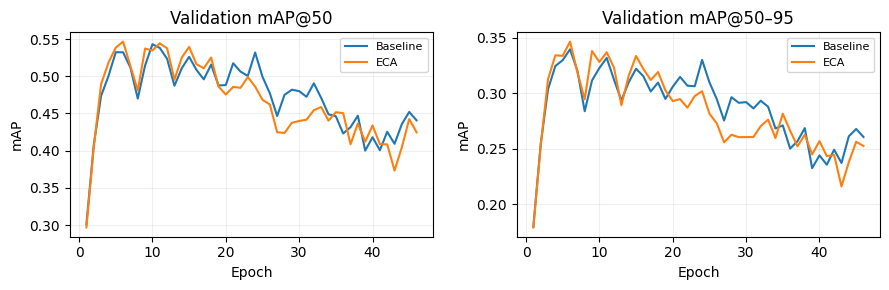

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

runs = {
    "Baseline": RUNS / "baseline_yolov8s_v3_tuned_v1",
    "ECA": RUNS / "original_yolov8s_eca_v1",
}

fig, axes = plt.subplots(1, 2, figsize=(9, 3))

for name, folder in runs.items():
    history = pd.read_csv(folder / "results.csv")
    history.columns = history.columns.str.strip()

    for ax, column, title in [
        (axes[0], "metrics/mAP50(B)", "Validation mAP@50"),
        (axes[1], "metrics/mAP50-95(B)", "Validation mAP@50–95"),
    ]:
        ax.plot(history["epoch"], history[column], label=name)
        ax.set(title=title, xlabel="Epoch", ylabel="mAP")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES / "validation_learning_curves.png", dpi=200)
plt.show()

comparision

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


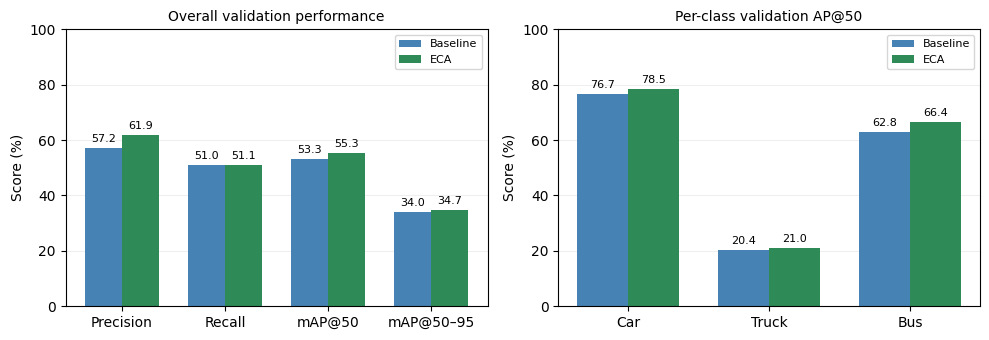

Graph saved: /content/drive/MyDrive/YOLO_vehicle_experiments/final_figures/baseline_vs_eca_validation.png


In [10]:
from google.colab import drive
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/YOLO_vehicle_experiments")
OUTPUT = ROOT / "final_figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

folders = {
    "Baseline": "baseline_yolov8s_v3_tuned_v1",
    "ECA": "original_yolov8s_eca_v1",
}

results = {}
for name, folder in folders.items():
    path = ROOT / folder / "validation_summary.json"
    assert path.is_file(), f"Saved metrics missing: {path}"
    results[name] = json.loads(path.read_text())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
width = 0.36
colors = ["steelblue", "seagreen"]

groups = [
    (
        axes[0],
        ["Precision", "Recall", "mAP@50", "mAP@50–95"],
        lambda r: [
            r["precision"], r["recall"], r["mAP50"], r["mAP50_95"]
        ],
        "Overall validation performance",
    ),
    (
        axes[1],
        ["Car", "Truck", "Bus"],
        lambda r: [
            r["per_class"][c]["AP50"] for c in ["car", "truck", "bus"]
        ],
        "Per-class validation AP@50",
    ),
]

for ax, labels, get_values, title in groups:
    x = np.arange(len(labels))

    for i, (name, result) in enumerate(results.items()):
        values = np.array(get_values(result)) * 100
        bars = ax.bar(
            x + (i - 0.5) * width,
            values,
            width,
            label=name,
            color=colors[i],
        )
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=3)

    ax.set_xticks(x, labels)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Score (%)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.tight_layout()
path = OUTPUT / "baseline_vs_eca_validation.png"
fig.savefig(path, dpi=250, bbox_inches="tight")
plt.show()

print("Graph saved:", path)